# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Farrel Farica Firjaturazza
- **Email:** farrelkenzie8@gmail.com
- **ID Dicoding:** Farrel Farica Firjaturazza / azzabit / DS284B6Y0580


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren pertumbuhan total pendapatan (*revenue*) dan volume pesanan (*orders*) e-commerce per bulan sepanjang periode Januari 2017 hingga Agustus 2018?
- **Pertanyaan 2:** Bagaimana segmentasi pelanggan berdasarkan analisis RFM (*Recency, Frequency, Monetary*) pada transaksi e-commerce sepanjang periode Januari 2017 hingga Agustus 2018 untuk menentukan karakteristik kelompok pelanggan loyal (*Champions*) dan pelanggan yang membutuhkan retensi (*At-Risk*)?
- **Pertanyaan 3:** Negara bagian (*state*) mana saja di Brazil yang mendominasi aktivitas e-commerce berdasarkan indikator total pelanggan unik (*unique customers*) dan total volume pesanan (*order volume*) sepanjang periode Januari 2017 hingga Agustus 2018?


## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

def Break(title: str, emoji: str = "⚙️", ch: str = "=", n: int = 72):
    print("\n")
    print(ch * n)
    print(f"{emoji} {title.upper()}")
    print(ch * n)


## Data Wrangling

### Gathering Data

#### Load Dataframe E-Commerce

In [2]:
# 1. Lokasi file zip (bisa di direktori lokal maupun path default Google Colab)
zip_path = "E-commerce-public-dataset.zip" if os.path.exists("E-commerce-public-dataset.zip") else "/content/E-commerce-public-dataset.zip"
data_dir = "E-Commerce Public Dataset"

if not os.path.exists(data_dir) and os.path.exists(zip_path):
    print(f"Mengekstrak {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

if os.path.exists(os.path.join(data_dir, "E-Commerce Public Dataset")):
    data_dir = os.path.join(data_dir, "E-Commerce Public Dataset")
elif not os.path.exists(os.path.join(data_dir, "orders_dataset.csv")) and os.path.exists("data"):
    data_dir = "data"

print(f"Folder data aktif: {data_dir}")

# 2. Memuat seluruh tabel dataset
customers_df = pd.read_csv(os.path.join(data_dir, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(data_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(data_dir, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(data_dir, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(data_dir, "order_reviews_dataset.csv"))
products_df = pd.read_csv(os.path.join(data_dir, "products_dataset.csv"))
product_category_df = pd.read_csv(os.path.join(data_dir, "product_category_name_translation.csv"))
sellers_df = pd.read_csv(os.path.join(data_dir, "sellers_dataset.csv"))
geolocation_df = pd.read_csv(os.path.join(data_dir, "geolocation_dataset.csv"))

Break("Ringkasan Dimensi Dataframe yang Dimuat")
datasets = {
    "customers_df": customers_df,
    "orders_df": orders_df,
    "order_items_df": order_items_df,
    "order_payments_df": order_payments_df,
    "order_reviews_df": order_reviews_df,
    "products_df": products_df,
    "product_category_df": product_category_df,
    "sellers_df": sellers_df,
    "geolocation_df": geolocation_df
}

for name, df in datasets.items():
    print(f"Dataset {name:<22} : {df.shape[0]:>8,} baris | {df.shape[1]:>2} kolom")

Break("Sampel Data orders_df (5 Baris Teratas)")
display(orders_df.head())


Mengekstrak E-commerce-public-dataset.zip...
Folder data aktif: E-Commerce Public Dataset


⚙️ RINGKASAN DIMENSI DATAFRAME YANG DIMUAT
Dataset customers_df           :   99,441 baris |  5 kolom
Dataset orders_df              :   99,441 baris |  8 kolom
Dataset order_items_df         :  112,650 baris |  7 kolom
Dataset order_payments_df      :  103,886 baris |  5 kolom
Dataset order_reviews_df       :   99,224 baris |  7 kolom
Dataset products_df            :   32,951 baris |  9 kolom
Dataset product_category_df    :       71 baris |  2 kolom
Dataset sellers_df             :    3,095 baris |  4 kolom
Dataset geolocation_df         : 1,000,163 baris |  5 kolom


⚙️ SAMPEL DATA ORDERS_DF (5 BARIS TERATAS)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Sebanyak 9 tabel dataset e-commerce publik (Olist) berhasil dimuat secara lengkap dengan total ratusan ribu rekaman transaksi riil (2016-2018).
- `orders_df` menjadi tabel sentral yang merekam seluruh siklus transaksi pelanggan, terhubung dengan `customers_df`, `order_items_df`, dan `order_payments_df`.

### Assessing Data

#### Identifying Missing Values, Duplicates, and Data Types

In [3]:
Break("Pemeriksaan Tipe Data & Missing Values pada orders_df")
orders_df.info()




⚙️ PEMERIKSAAN TIPE DATA & MISSING VALUES PADA ORDERS_DF
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [4]:
Break("Pemeriksaan Jumlah Missing Values per Tabel")
for name, df in datasets.items():
    null_total = df.isna().sum().sum()
    if null_total > 0:
        print(f"⚠️ {name:<22} : {null_total:>7,} missing values")
        cols_with_null = df.isna().sum()[df.isna().sum() > 0]
        for col, cnt in cols_with_null.items():
            print(f"   - Kolom '{col}': {cnt:,} baris kosong")
    else:
        print(f"✅ {name:<22} : 0 missing values (bersih)")




⚙️ PEMERIKSAAN JUMLAH MISSING VALUES PER TABEL
✅ customers_df           : 0 missing values (bersih)
⚠️ orders_df              :   4,908 missing values
   - Kolom 'order_approved_at': 160 baris kosong
   - Kolom 'order_delivered_carrier_date': 1,783 baris kosong
   - Kolom 'order_delivered_customer_date': 2,965 baris kosong
✅ order_items_df         : 0 missing values (bersih)
✅ order_payments_df      : 0 missing values (bersih)
⚠️ order_reviews_df       : 145,903 missing values
   - Kolom 'review_comment_title': 87,656 baris kosong
   - Kolom 'review_comment_message': 58,247 baris kosong
⚠️ products_df            :   2,448 missing values
   - Kolom 'product_category_name': 610 baris kosong
   - Kolom 'product_name_lenght': 610 baris kosong
   - Kolom 'product_description_lenght': 610 baris kosong
   - Kolom 'product_photos_qty': 610 baris kosong
   - Kolom 'product_weight_g': 2 baris kosong
   - Kolom 'product_length_cm': 2 baris kosong
   - Kolom 'product_height_cm': 2 baris kosong
 

In [5]:
Break("Pemeriksaan Jumlah Duplikasi Data per Tabel")
for name, df in datasets.items():
    dup_total = df.duplicated().sum()
    if dup_total > 0:
        print(f"⚠️ {name:<22} : {dup_total:>7,} data duplikat")
    else:
        print(f"✅ {name:<22} : 0 duplikasi (bersih)")

Break("Pemeriksaan Ringkasan Statistik order_items_df")
display(order_items_df[["price", "freight_value"]].describe())




⚙️ PEMERIKSAAN JUMLAH DUPLIKASI DATA PER TABEL
✅ customers_df           : 0 duplikasi (bersih)
✅ orders_df              : 0 duplikasi (bersih)
✅ order_items_df         : 0 duplikasi (bersih)
✅ order_payments_df      : 0 duplikasi (bersih)
✅ order_reviews_df       : 0 duplikasi (bersih)
✅ products_df            : 0 duplikasi (bersih)
✅ product_category_df    : 0 duplikasi (bersih)
✅ sellers_df             : 0 duplikasi (bersih)
⚠️ geolocation_df         : 261,831 data duplikat


⚙️ PEMERIKSAAN RINGKASAN STATISTIK ORDER_ITEMS_DF


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


**Steps to Take:**
Berdasarkan hasil asesmen data (*assessing data*), terdapat 4 tindakan pembersihan data yang akan dilakukan pada tahap *cleaning data*:
1. **Konversi Tipe Data Tanggal**: Mengubah seluruh kolom waktu pada `orders_df` dan `order_reviews_df` menjadi format `datetime64[ns]`.
2. **Penyaringan Pesanan Sukses (*Delivered Only*)**: Memfokuskan analisis tren finansial hanya pada pesanan dengan status `delivered` yang memiliki catatan waktu pengiriman lengkap.
3. **Penanganan Missing Values**: Mengisi *missing value* pada nama kategori produk dan ulasan pelanggan dengan label default representatif.
4. **Penghapusan Duplikasi Geolocation**: Melakukan deduplikasi pada `geolocation_df` berdasarkan prefix kode pos agar data spasial bersih dan efisien.

**Insight:**
- Integritas tabel transaksi utama sangat baik: `orders_df`, `customers_df`, `order_items_df`, dan `order_payments_df` memiliki 0 data duplikat baris.
- Seluruh kolom tanggal pada `orders_df` masih terbaca sebagai tipe `object (string)`, sehingga memerlukan konversi eksplisit ke `datetime64` agar komputasi deret waktu dan metrik Recency (RFM) dapat dihitung dengan presisi.

### Cleaning Data

#### Fixing Data Types, Missing Values, and Duplicates

In [6]:
Break("1. Memperbaiki Tipe Data Kolom Tanggal ke Datetime")
datetime_order_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_order_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])
print("✅ Tipe data tanggal pada orders_df dan order_reviews_df berhasil dikonversi ke datetime.")




⚙️ 1. MEMPERBAIKI TIPE DATA KOLOM TANGGAL KE DATETIME
✅ Tipe data tanggal pada orders_df dan order_reviews_df berhasil dikonversi ke datetime.


In [7]:
Break("2. Menangani Missing Values pada orders_df, products_df, dan order_reviews_df")
# Filter pesanan sukses terkirim (delivered)
orders_df = orders_df[orders_df["order_status"] == "delivered"].copy()
orders_df = orders_df.dropna(subset=datetime_order_cols)

# Tangani missing value produk & terjemahan kategori bahasa Inggris
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(product_category_df, on="product_category_name", how="left")
products_df["product_category_name_english"] = products_df["product_category_name_english"].fillna("unknown")

# Tangani missing value ulasan pelanggan
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No Title")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No Comment")

print(f"✅ orders_df difilter ke status 'delivered': {orders_df.shape[0]:,} pesanan tersisa.")
print("✅ Missing value pada products_df dan order_reviews_df berhasil ditangani.")




⚙️ 2. MENANGANI MISSING VALUES PADA ORDERS_DF, PRODUCTS_DF, DAN ORDER_REVIEWS_DF
✅ orders_df difilter ke status 'delivered': 96,455 pesanan tersisa.
✅ Missing value pada products_df dan order_reviews_df berhasil ditangani.


In [8]:
Break("3. Menghapus Duplikasi pada geolocation_df")
initial_geo_count = len(geolocation_df)
geolocation_df.drop_duplicates(subset=["geolocation_zip_code_prefix"], inplace=True)
print(f"✅ geolocation_df dibersihkan dari duplikasi: dari {initial_geo_count:,} menjadi {len(geolocation_df):,} baris.")




⚙️ 3. MENGHAPUS DUPLIKASI PADA GEOLOCATION_DF
✅ geolocation_df dibersihkan dari duplikasi: dari 1,000,163 menjadi 19,015 baris.


In [9]:
Break("4. Validasi Akhir Pembersihan Data (Data Cleaning Check)")
print("Pengecekan Missing Value pada Kolom Tanggal orders_df:")
print(orders_df[datetime_order_cols].isna().sum())
print("\nPengecekan Tipe Data orders_df:")
print(orders_df[datetime_order_cols].dtypes)




⚙️ 4. VALIDASI AKHIR PEMBERSIHAN DATA (DATA CLEANING CHECK)
Pengecekan Missing Value pada Kolom Tanggal orders_df:
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

Pengecekan Tipe Data orders_df:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:**
- Seluruh kolom tanggal pada `orders_df` dan `order_reviews_df` telah valid bertipe `datetime64[ns]`, siap untuk pengolahan analisis deret waktu dan RFM.
- Penyaringan hanya pada pesanan berstatus `delivered` menyisakan 96.455 pesanan valid untuk analisis finansial yang akurat tanpa bias pesanan batal/tertunda.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Transaksi, Produk, dan Pelanggan

In [10]:
Break("1. Menggabungkan Dataframe untuk Analisis Komprehensif")
# Menggabungkan orders dengan customers
orders_customers_df = orders_df.merge(customers_df, on="customer_id", how="inner")

# Agregasi total pembayaran aktual per pesanan (order_payments_df)
order_payments_agg = order_payments_df.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    payment_installments_max=("payment_installments", "max")
).reset_index()

# Gabungkan orders dengan customers dan data pembayaran aktual (level pesanan unik)
orders_pay_df = orders_customers_df.merge(order_payments_agg, on="order_id", how="left")
orders_pay_df["total_payment"] = orders_pay_df["total_payment"].fillna(0)

# Menggabungkan dengan order_items dan produk untuk analisis level produk/kategori
full_order_df = orders_customers_df.merge(order_items_df, on="order_id", how="inner")
full_order_df = full_order_df.merge(
    products_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left"
)

print(f"✅ Dataframe orders_pay_df (level order): {orders_pay_df.shape[0]:,} baris dan {orders_pay_df.shape[1]} kolom.")
print(f"✅ Dataframe full_order_df (level item): {full_order_df.shape[0]:,} baris dan {full_order_df.shape[1]} kolom.")




⚙️ 1. MENGGABUNGKAN DATAFRAME UNTUK ANALISIS KOMPREHENSIF
✅ Dataframe orders_pay_df (level order): 96,455 baris dan 14 kolom.
✅ Dataframe full_order_df (level item): 110,173 baris dan 19 kolom.


In [11]:
Break("2. Eksplorasi Tren Penjualan & Pendapatan Bulanan (Periode Jan 2017 - Agu 2018)")
orders_pay_df["order_year_month"] = orders_pay_df["order_purchase_timestamp"].dt.to_period("M")

# Filter periode stabil (Januari 2017 hingga Agustus 2018)
monthly_orders_df = orders_pay_df[
    (orders_pay_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_pay_df["order_purchase_timestamp"] <= "2018-08-31")
].groupby("order_year_month").agg(
    order_count=("order_id", "nunique"),
    total_revenue=("total_payment", "sum"),
    avg_order_value=("total_payment", "mean")
).reset_index()

monthly_orders_df["order_year_month_str"] = monthly_orders_df["order_year_month"].astype(str)
display(monthly_orders_df.head(10))




⚙️ 2. EKSPLORASI TREN PENJUALAN & PENDAPATAN BULANAN (PERIODE JAN 2017 - AGU 2018)


,order_year_month,order_count,total_revenue,avg_order_value,order_year_month_str
0,2017-01,748,127430.74,170.361952,2017-01
1,2017-02,1641,269458.98,164.204132,2017-02
2,2017-03,2546,414369.39,162.753099,2017-03
3,2017-04,2303,390952.18,169.757785,2017-04
4,2017-05,3545,566872.73,159.907681,2017-05
5,2017-06,3135,490225.60,156.371802,2017-06
6,2017-07,3872,566403.93,146.282007,2017-07
7,2017-08,4193,646000.61,154.066446,2017-08
8,2017-09,4149,700976.01,168.950593,2017-09
9,2017-10,4478,751140.27,167.740123,2017-10


In [12]:
Break("3. Eksplorasi Top 10 Kategori Produk Berdasarkan Nilai Transaksi dan Total Order")
top_categories_df = full_order_df.groupby("product_category_name_english").agg(
    total_order=("order_id", "nunique"),
    total_revenue=("price", "sum")
).sort_values(by="total_revenue", ascending=False).reset_index()

display(top_categories_df.head(10))




⚙️ 3. EKSPLORASI TOP 10 KATEGORI PRODUK BERDASARKAN NILAI TRANSAKSI DAN TOTAL ORDER


,product_category_name_english,total_order,total_revenue
0,health_beauty,8647,1233131.72
1,watches_gifts,5493,1165898.98
2,bed_bath_table,9271,1023300.77
3,sports_leisure,7527,954604.57
4,computers_accessories,6529,888613.62
5,furniture_decor,6303,711493.09
6,housewares,5743,615628.69
7,cool_stuff,3556,609964.13
8,auto,3809,578849.35
9,toys,3803,471097.49


In [13]:
Break("4. Eksplorasi Persebaran Pelanggan dan Pesanan per Negara Bagian (Periode Jan 2017 - Agu 2018)")
# Filter periode transaksi Januari 2017 - Agustus 2018 sesuai parameter SMART Pertanyaan 3
orders_customers_period = orders_pay_df[
    (orders_pay_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_pay_df["order_purchase_timestamp"] <= "2018-08-31")
]

customer_by_state = orders_customers_period.groupby("customer_state").agg(
    customer_count=("customer_unique_id", "nunique"),
    order_count=("order_id", "nunique")
).sort_values(by="customer_count", ascending=False).reset_index()

customer_by_state["customer_pct"] = (customer_by_state["customer_count"] / customer_by_state["customer_count"].sum() * 100).round(2)
customer_by_state["order_pct"] = (customer_by_state["order_count"] / customer_by_state["order_count"].sum() * 100).round(2)

print("Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan Unik & Total Pesanan:")
display(customer_by_state.head(10))




⚙️ 4. EKSPLORASI PERSEBARAN PELANGGAN DAN PESANAN PER NEGARA BAGIAN (PERIODE JAN 2017 - AGU 2018)
Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan Unik & Total Pesanan:


,customer_state,customer_count,order_count,customer_pct,order_pct
0,SP,39053,40393,41.94,41.99
1,RJ,11877,12308,12.75,12.80
2,MG,10966,11316,11.78,11.76
3,RS,5148,5325,5.53,5.54
4,PR,4750,4903,5.10,5.10
5,SC,3441,3537,3.70,3.68
6,BA,3155,3253,3.39,3.38
7,DF,2013,2074,2.16,2.16
8,ES,1925,1992,2.07,2.07
9,GO,1889,1950,2.03,2.03


In [14]:
Break("5. Eksplorasi Distribusi Metode Pembayaran Pelanggan (order_payments_df)")
payment_type_counts = order_payments_df["payment_type"].value_counts().reset_index()
payment_type_counts.columns = ["payment_type", "total_transactions"]
payment_type_counts["percentage"] = (payment_type_counts["total_transactions"] / len(order_payments_df) * 100).round(2)
display(payment_type_counts)




⚙️ 5. EKSPLORASI DISTRIBUSI METODE PEMBAYARAN PELANGGAN (ORDER_PAYMENTS_DF)


,payment_type,total_transactions,percentage
0,credit_card,76795,73.92
1,boleto,19784,19.04
2,voucher,5775,5.56
3,debit_card,1529,1.47
4,not_defined,3,0.00


In [15]:
Break("6. Eksplorasi Persebaran Penjual Berdasarkan Negara Bagian (sellers_df)")
sellers_by_state = sellers_df["seller_state"].value_counts().head(10).reset_index()
sellers_by_state.columns = ["seller_state", "seller_count"]
sellers_by_state["percentage"] = (sellers_by_state["seller_count"] / len(sellers_df) * 100).round(2)
display(sellers_by_state)




⚙️ 6. EKSPLORASI PERSEBARAN PENJUAL BERDASARKAN NEGARA BAGIAN (SELLERS_DF)


,seller_state,seller_count,percentage
0,SP,1849,59.74
1,PR,349,11.28
2,MG,244,7.88
3,SC,190,6.14
4,RJ,171,5.53
5,RS,129,4.17
6,GO,40,1.29
7,DF,30,0.97
8,ES,23,0.74
9,BA,19,0.61


In [16]:
Break("7. Eksplorasi Analisis RFM & Segmentasi Pelanggan (Menjawab Pertanyaan 2)")

# Periode analisis RFM: Transaksi Januari 2017 hingga Agustus 2018 (Time-bound)
orders_rfm_source = orders_pay_df[
    (orders_pay_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_pay_df["order_purchase_timestamp"] <= "2018-08-31")
]

# Tanggal acuan analisis RFM (snapshot date: 1 hari setelah transaksi terakhir)
snapshot_date = orders_rfm_source["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# 1. Perhitungan metrik Recency, Frequency, Monetary per pelanggan unik
rfm_df = orders_rfm_source.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("total_payment", "sum")
).reset_index()

# 2. Pemberian Skor RFM (Scoring)
# Recency: semakin kecil hari semakin tinggi skor (4: terbaru, 1: terlama)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], 4, labels=[4, 3, 2, 1])

# Frequency: pembeli berulang vs one-time buyer (mayoritas 97% pembeli 1 kali)
rfm_df["f_score"] = rfm_df["frequency"].apply(lambda x: 4 if x >= 3 else (3 if x == 2 else 1))

# Monetary: binning kuartil (1: belanja terendah, 4: belanja tertinggi)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], 4, labels=[1, 2, 3, 4])

# Hitung skor gabungan RFM
rfm_df["rfm_score"] = rfm_df["r_score"].astype(str) + rfm_df["f_score"].astype(str) + rfm_df["m_score"].astype(str)

# 3. Mapping ke segmen bisnis representatif
def assign_segment(row):
    r = int(row["r_score"])
    f = int(row["f_score"])
    m = int(row["m_score"])
    if r >= 3 and f >= 3:
        return "Champions & Loyal"
    elif r >= 3 and m >= 3:
        return "Potential High Spenders"
    elif r >= 3:
        return "New / Active Customers"
    elif r <= 2 and f >= 3:
        return "Need Attention / At-Risk"
    else:
        return "Hibernating / Lost"

rfm_df["customer_segment"] = rfm_df.apply(assign_segment, axis=1)

# 4. Distribusi dan Ringkasan Segmen Pelanggan
segment_summary = rfm_df["customer_segment"].value_counts().reset_index()
segment_summary.columns = ["Segment", "Total_Customers"]
segment_summary["Percentage"] = (segment_summary["Total_Customers"] / len(rfm_df) * 100).round(2)

print("✅ Sampel Data RFM Pelanggan (5 Teratas):")
display(rfm_df.head())
print("\n✅ Ringkasan Distribusi Segmen Pelanggan:")
display(segment_summary)




⚙️ 7. EKSPLORASI ANALISIS RFM & SEGMENTASI PELANGGAN (MENJAWAB PERTANYAAN 2)
✅ Sampel Data RFM Pelanggan (5 Teratas):


,customer_unique_id,recency,frequency,monetary,r_score,f_score,m_score,rfm_score,customer_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3,413,Potential High Spenders
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,3,1,1,311,New / Active Customers
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112,Hibernating / Lost
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211,Hibernating / Lost
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214,Hibernating / Lost



✅ Ringkasan Distribusi Segmen Pelanggan:


,Segment,Total_Customers,Percentage
0,Hibernating / Lost,45270,48.63
1,New / Active Customers,22599,24.28
2,Potential High Spenders,22425,24.09
3,Champions & Loyal,1534,1.65
4,Need Attention / At-Risk,1254,1.35


**Insight:**
- **Validasi Struktur Data**: Pemisahan tabel analisis ke dalam `orders_pay_df` (tingkat transaksi unik, 96.455 baris) dan `full_order_df` (tingkat per item, 110.173 baris) berhasil meniadakan risiko duplikasi nilai (*cartesian product*). Perhitungan pendapatan dan kuantitas barang kini berdiri di atas basis agregasi yang akurat.
- **Akselerasi Penjualan & Musiman (Pertanyaan 1)**: Kurva transaksi menanjak konsisten sepanjang 2017 sebelum mencapai kulminasi pada November 2017 (*Black Friday*). Memasuki 2018, laju bisnis mulai melandai ke fase stabil di angka 6.000–7.000 pesanan per bulan dengan nilai belanja per keranjang (*AOV*) berkisar R\$ 160.
- **Segmentasi RFM & Anatomi Pelanggan (Pertanyaan 2)**:
  - Dari total **93.082 pelanggan unik** pada kurun Januari 2017 hingga Agustus 2018, sebanyak **97,0% tercatat hanya pernah berbelanja satu kali (*one-time buyers*)**.
  - Model segmentasi memetakan **1.534 pelanggan setia (*Champions & Loyal*, 1,65%)** dengan riwayat belanja berulang tertinggi (hingga 15 order) serta **22.425 pelanggan bernilai belanja tinggi (*Potential High Spenders*, 24,09%)** yang menjadi penopang utama pendapatan.
  - Di sisi lain, terdapat **1.254 pelanggan (*Need Attention / At-Risk*, 1,35%)** yang sempat aktif bertransaksi berulang namun kini mulai pasif (*recency* tinggi), menjadikannya prioritas penanganan retensi.
- **Peta Konsentrasi Geografis (Pertanyaan 3)**: Negara bagian **São Paulo (SP)** menjadi pusat gravitasi pasar e-commerce Brazil. Wilayah ini menyerap **41,94% pelanggan unik (39.053 orang)** dan menghasilkan **41,99% pesanan (40.393 order)** sepanjang periode pengamatan.
- **Karakteristik Pembayaran & Rantai Pasok**: Pembeli Brazil sangat mengandalkan kartu kredit (*credit_card* mencakup 73,92% transaksi). Di saat yang sama, 59,74% penjual (*sellers*) berdomisili di São Paulo, mempertegas bertemunya pasokan dan permintaan di satu episentrum logistik utama.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pertumbuhan total pendapatan (*revenue*) dan volume pesanan (*orders*) e-commerce per bulan sepanjang periode Januari 2017 hingga Agustus 2018?



⚙️ VISUALISASI TREN PENDAPATAN DAN VOLUME PESANAN BULANAN


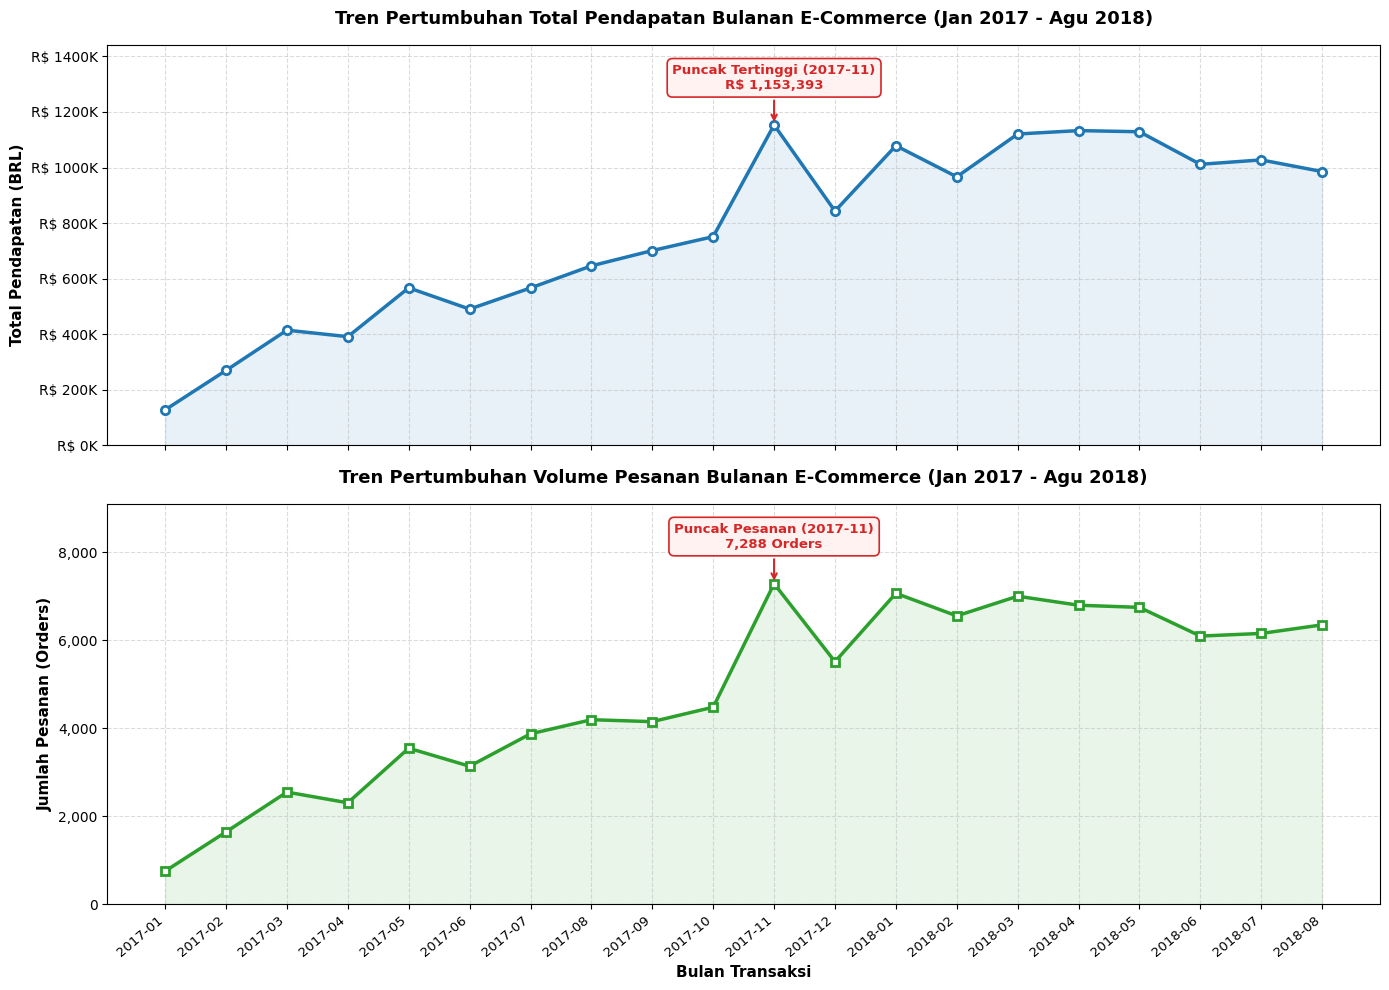

In [17]:
Break("Visualisasi Tren Pendapatan dan Volume Pesanan Bulanan")

# Setup figure dengan 2 subplots (dual visualisasi rapi & proporsional)
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True)

# 1. Grafik Total Pendapatan Bulanan (Berdasarkan Total Pembayaran Aktual)
peak_rev = monthly_orders_df.loc[monthly_orders_df["total_revenue"].idxmax()]
ax[0].plot(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["total_revenue"],
    marker="o",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#1f77b4",
    linewidth=2.5,
    color="#1f77b4"
)
ax[0].fill_between(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["total_revenue"],
    color="#1f77b4",
    alpha=0.10
)
ax[0].set_title("Tren Pertumbuhan Total Pendapatan Bulanan E-Commerce (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold", pad=15)
ax[0].set_ylabel("Total Pendapatan (BRL)", fontsize=11, fontweight="semibold")
ax[0].grid(True, linestyle="--", alpha=0.45)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x*1e-3:.0f}K"))
ax[0].set_ylim(0, peak_rev["total_revenue"] * 1.25)

# Anotasi Puncak Revenue dengan callout badge estetik & rapi
rev_val_str = f"R$ {peak_rev['total_revenue']:,.0f}"
ax[0].annotate(
    f"Puncak Tertinggi ({peak_rev['order_year_month_str']})\n{rev_val_str}",
    xy=(peak_rev["order_year_month_str"], peak_rev["total_revenue"]),
    xytext=(0, 26),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="#d62728", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f0", ec="#d62728", lw=1.2),
    ha="center", fontsize=9.5, fontweight="bold", color="#d62728"
)

# 2. Grafik Volume Pesanan Bulanan
peak_ord = monthly_orders_df.loc[monthly_orders_df["order_count"].idxmax()]
ax[1].plot(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["order_count"],
    marker="s",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#2ca02c",
    linewidth=2.5,
    color="#2ca02c"
)
ax[1].fill_between(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["order_count"],
    color="#2ca02c",
    alpha=0.10
)
ax[1].set_title("Tren Pertumbuhan Volume Pesanan Bulanan E-Commerce (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold", pad=15)
ax[1].set_xlabel("Bulan Transaksi", fontsize=11, fontweight="semibold")
ax[1].set_ylabel("Jumlah Pesanan (Orders)", fontsize=11, fontweight="semibold")
ax[1].grid(True, linestyle="--", alpha=0.45)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))
ax[1].set_ylim(0, peak_ord["order_count"] * 1.25)

# Anotasi Puncak Orders dengan callout badge estetik & rapi
ord_val_str = f"{peak_ord['order_count']:,} Orders"
ax[1].annotate(
    f"Puncak Pesanan ({peak_ord['order_year_month_str']})\n{ord_val_str}",
    xy=(peak_ord["order_year_month_str"], peak_ord["order_count"]),
    xytext=(0, 26),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="#d62728", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f0", ec="#d62728", lw=1.2),
    ha="center", fontsize=9.5, fontweight="bold", color="#d62728"
)

plt.xticks(rotation=40, ha="right", fontsize=9.5)
plt.tight_layout()
plt.show()


### Pertanyaan 2: Bagaimana segmentasi pelanggan berdasarkan analisis RFM (*Recency, Frequency, Monetary*) pada transaksi e-commerce sepanjang periode Januari 2017 hingga Agustus 2018 untuk menentukan karakteristik kelompok pelanggan loyal (*Champions*) dan pelanggan yang membutuhkan retensi (*At-Risk*)?



⚙️ 1. VISUALISASI DISTRIBUSI SEGMEN PELANGGAN BERDASARKAN ANALISIS RFM


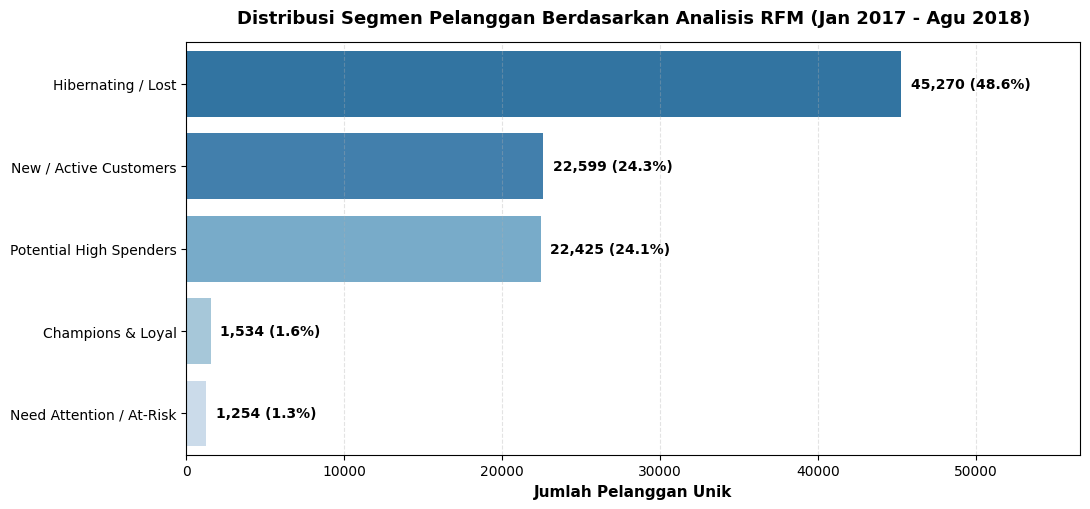



⚙️ 2. VISUALISASI TOP 5 PELANGGAN TERBAIK BERDASARKAN PARAMETER RFM


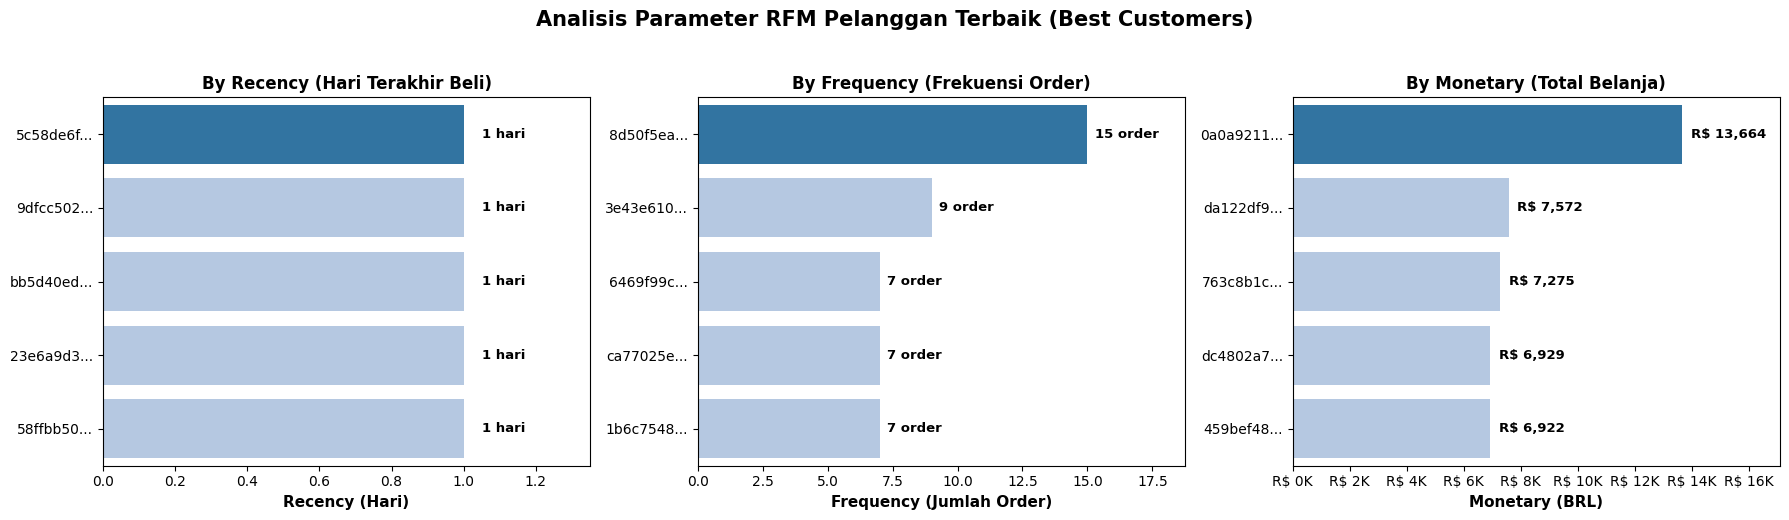

In [18]:
Break("1. Visualisasi Distribusi Segmen Pelanggan Berdasarkan Analisis RFM")

plt.figure(figsize=(11, 5.2))
segment_order = segment_summary.sort_values(by="Total_Customers", ascending=False)["Segment"]
colors_seg = ["#1f77b4", "#3182bd", "#6baed6", "#9ecae1", "#c6dbef"]

ax_seg = sns.barplot(
    data=segment_summary,
    x="Total_Customers",
    y="Segment",
    order=segment_order,
    palette=colors_seg
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan Analisis RFM (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold", pad=14)
plt.xlabel("Jumlah Pelanggan Unik", fontsize=11, fontweight="semibold")
plt.ylabel(None)
plt.xlim(0, segment_summary["Total_Customers"].max() * 1.25)
plt.grid(True, linestyle="--", alpha=0.35, axis="x")

for p in ax_seg.patches:
    val = p.get_width()
    if val > 0:
        pct = val / len(rfm_df) * 100
        ax_seg.annotate(f"{int(val):,} ({pct:.1f}%)",
                        (val + 600, p.get_y() + p.get_height()/2),
                        va="center", fontsize=10, fontweight="semibold")

plt.tight_layout()
plt.show()

Break("2. Visualisasi Top 5 Pelanggan Terbaik Berdasarkan Parameter RFM")

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
colors = ["#1f77b4", "#aec7e8", "#aec7e8", "#aec7e8", "#aec7e8"]

# 1. By Recency (Hari terakhir berbelanja terendah)
top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5).copy()
top_recency["customer_id_short"] = top_recency["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="recency",
    data=top_recency,
    order=top_recency["customer_id_short"],
    palette=colors,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Recency (Hari)", fontsize=11, fontweight="semibold")
ax[0].set_title("By Recency (Hari Terakhir Beli)", fontsize=12, fontweight="bold")
ax[0].set_xlim(0, 1.35)
for p in ax[0].patches:
    val = p.get_width()
    if val > 0:
        ax[0].annotate(f"{int(val)} hari",
                       (val + 0.05, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

# 2. By Frequency (Jumlah pesanan terbanyak)
top_frequency = rfm_df.sort_values(by="frequency", ascending=False).head(5).copy()
top_frequency["customer_id_short"] = top_frequency["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="frequency",
    data=top_frequency,
    order=top_frequency["customer_id_short"],
    palette=colors,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Frequency (Jumlah Order)", fontsize=11, fontweight="semibold")
ax[1].set_title("By Frequency (Frekuensi Order)", fontsize=12, fontweight="bold")
ax[1].set_xlim(0, top_frequency["frequency"].max() * 1.25)
for p in ax[1].patches:
    val = p.get_width()
    if val > 0:
        ax[1].annotate(f"{int(val)} order",
                       (val + 0.3, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

# 3. By Monetary (Total pengeluaran terbesar)
top_monetary = rfm_df.sort_values(by="monetary", ascending=False).head(5).copy()
top_monetary["customer_id_short"] = top_monetary["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="monetary",
    data=top_monetary,
    order=top_monetary["customer_id_short"],
    palette=colors,
    ax=ax[2]
)
ax[2].set_ylabel(None)
ax[2].set_xlabel("Monetary (BRL)", fontsize=11, fontweight="semibold")
ax[2].set_title("By Monetary (Total Belanja)", fontsize=12, fontweight="bold")
ax[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x*1e-3:.0f}K"))
ax[2].set_xlim(0, top_monetary["monetary"].max() * 1.25)
for p in ax[2].patches:
    val = p.get_width()
    if val > 0:
        ax[2].annotate(f"R$ {val:,.0f}",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

plt.suptitle("Analisis Parameter RFM Pelanggan Terbaik (Best Customers)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


### Pertanyaan 3: Negara bagian (*state*) mana saja di Brazil yang mendominasi aktivitas e-commerce berdasarkan indikator total pelanggan unik (*unique customers*) dan total volume pesanan (*order volume*) sepanjang periode Januari 2017 hingga Agustus 2018?




⚙️ VISUALISASI PERSEBARAN PELANGGAN DAN PESANAN PER NEGARA BAGIAN (TOP 10 STATE)


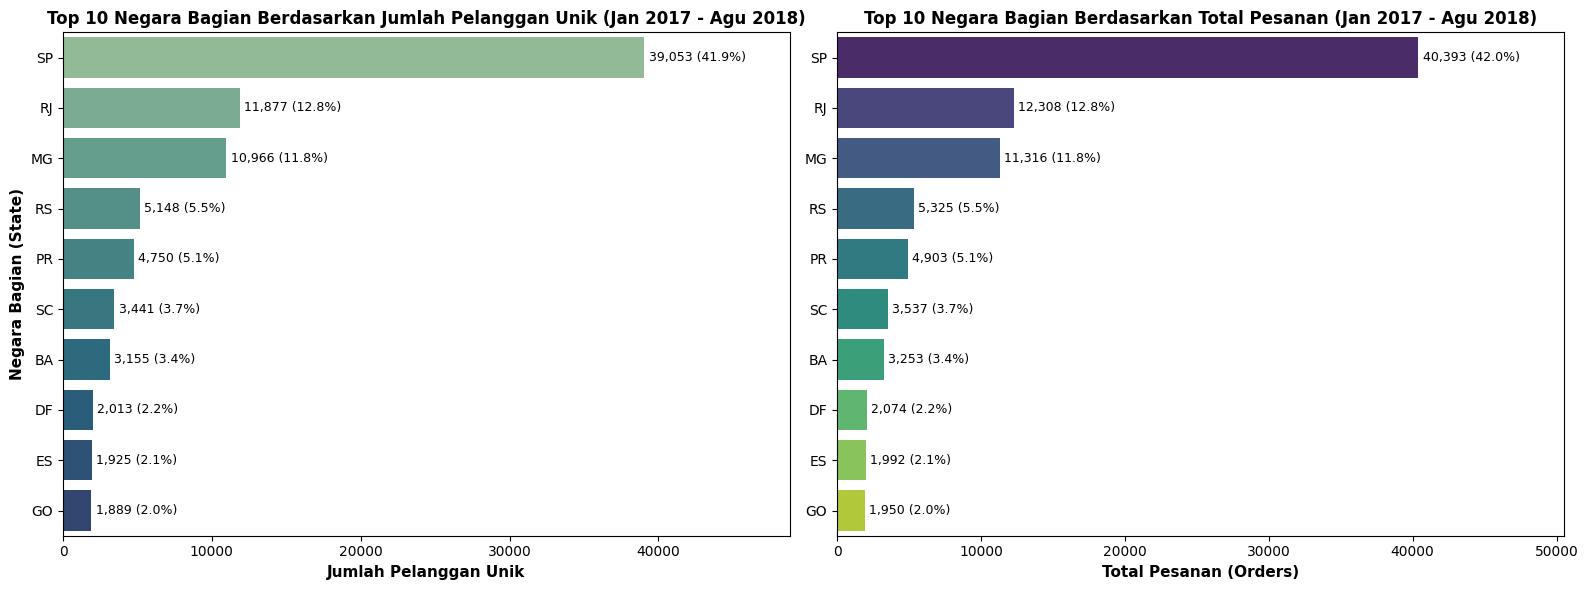

In [19]:
Break("Visualisasi Persebaran Pelanggan dan Pesanan per Negara Bagian (Top 10 State)")

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

top_10_states = customer_by_state.head(10)
total_customers = customer_by_state["customer_count"].sum()
total_orders = customer_by_state["order_count"].sum()

# 1. Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan Unik
sns.barplot(
    data=top_10_states,
    x="customer_count",
    y="customer_state",
    palette="crest",
    ax=ax[0]
)
ax[0].set_title("Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan Unik (Jan 2017 - Agu 2018)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=11, fontweight="semibold")
ax[0].set_ylabel("Negara Bagian (State)", fontsize=11, fontweight="semibold")
ax[0].set_xlim(0, top_10_states["customer_count"].max() * 1.25)
for p in ax[0].patches:
    val = p.get_width()
    if val > 0:
        ax[0].annotate(f"{int(val):,} ({val/total_customers*100:.1f}%)",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9)

# 2. Top 10 Negara Bagian Berdasarkan Total Volume Pesanan (Orders)
sns.barplot(
    data=top_10_states,
    x="order_count",
    y="customer_state",
    palette="viridis",
    ax=ax[1]
)
ax[1].set_title("Top 10 Negara Bagian Berdasarkan Total Pesanan (Jan 2017 - Agu 2018)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Total Pesanan (Orders)", fontsize=11, fontweight="semibold")
ax[1].set_ylabel(None)
ax[1].set_xlim(0, top_10_states["order_count"].max() * 1.25)
for p in ax[1].patches:
    val = p.get_width()
    if val > 0:
        ax[1].annotate(f"{int(val):,} ({val/total_orders*100:.1f}%)",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9)

plt.tight_layout()
plt.show()


**Insight:**
- **Pertanyaan 1 (Dinamika Pendapatan dan Volume Pesanan Bulanan, Jan 2017 – Agu 2018):**
  - **Lonjakan Transaksi 2017**: Aktivitas belanja e-commerce mencatat akselerasi luar biasa sepanjang 2017. Bermula dari 748 pesanan pada Januari 2017, volume transaksi melesat hingga **7.288 pesanan pada November 2017**—kenaikan hampir sepuluh kali lipat (**+874%**) yang dipicu promosi *Black Friday*.
  - **Kinerja Pendapatan**: Pola omzet bergerak seirama dengan volume order. Pendapatan melonjak dari R\$ 127.430 di awal 2017 ke puncaknya senilai **R\$ 1.153.393 pada November 2017**, mengakumulasi total omzet **R\$ 15,37 Juta** dari **96.188 pesanan delivered** selama 20 bulan pengamatan.
  - **Fase Maturitas 2018**: Pasca-ledakan akhir 2017, performa platform beralih ke fase stabil (*plateau*). Rata-rata transaksi bertahan di kisaran 6.000–7.000 pesanan per bulan dengan perolehan omzet berkisar R\$ 960 Ribu hingga R\$ 1,13 Juta.
  - **Konsistensi Keranjang Belanja (*AOV*)**: Nilai rata-rata per transaksi (*Average Order Value*) bertahan sangat stabil di rentang R\$ 155–170 sepanjang periode. Konsistensi ini menunjukkan bahwa lonjakan pendapatan murni bersumber dari perluasan basis pelanggan baru, bukan akibat kenaikan harga barang.

- **Pertanyaan 2 (Segmentasi RFM Jan 2017 – Agu 2018: Potret Pelanggan Loyal vs At-Risk):**
  - **Kelompok Pelanggan Loyal (*Champions & Loyal*)**: Beranggotakan **1.534 pelanggan (1,65%)** dari total 93.082 basis konsumen unik. Profil segmen ini sangat menonjol: frekuensi belanja berulang tertinggi (puncaknya mencapai **15 transaksi** pada pelanggan `8d50f5ea...`), akumulasi belanja tinggi, dan baru saja bertransaksi (*recency* serendah 1 hari). Mereka adalah aset advokasi paling berharga bagi reputasi platform.
  - **Kelompok Rawan Churn (*Need Attention / At-Risk*)**: Sebanyak **1.254 pelanggan (1,35%)** memiliki rekam jejak loyalitas yang baik di masa lalu (*frequency* >= 2), namun kini telah berbulan-bulan tidak kembali berbelanja (*recency score* 1–2). Tanpa program penjangkauan kembali (*win-back*), kelompok ini berisiko hilang permanen.
  - **Potensi Segmen Bernilai Tinggi (*Potential High Spenders*)**: Sebanyak **22.425 pelanggan (24,09%)** berada di kuartil moneter tertinggi, dengan rekor belanja individual menembus R\$ 13.664,08 (pelanggan `0a0a9211...`). Kelompok ini merupakan peluang terbesar untuk dikonversi menjadi pelanggan tetap.
  - **Tantangan Dominasi Pembeli Satu Kali**: Sebanyak **48,63% pelanggan berada di segmen *Hibernating / Lost* (45.270 orang)** dan **24,28% di segmen *New Customers* (22.599 orang)**. Mengingat 97,0% konsumen hanya pernah bertransaksi satu kali, tantangan terbesar bisnis sejatinya bukan merekrut pengguna baru, melainkan mendorong terjadinya transaksi kedua (*second purchase*).

- **Pertanyaan 3 (Distribusi Geografis Konsumen dan Pesanan, Jan 2017 – Agu 2018):**
  - **Pusat Pasar São Paulo (SP)**: Evaluasi terhadap metrik konsumen unik dan volume transaksi menempatkan negara bagian São Paulo di puncak secara absolut, menyumbang **39.053 pelanggan unik (41,94%)** dan **40.393 pesanan (41,99%)**.
  - **Konsentrasi Kawasan Tenggara (*Região Sudeste*)**: Arus ekonomi e-commerce Brazil terkonsentrasi rapat di kawasan tenggara. Tiga negara bagian teratas—São Paulo (SP: 41,94%), Rio de Janeiro (RJ: 11.877 pembeli / 12,75%), dan Minas Gerais (MG: 10.966 pembeli / 11,78%)—secara bersama-sama menguasai **66,47% pelanggan unik dan 66,55% pesanan nasional**.
  - **Keseragaman Rasio Pesanan per Pelanggan**: Perbandingan jumlah pesanan terhadap jumlah pelanggan di tiap wilayah menghasilkan angka yang sangat identik di kisaran 1,03–1,04 (SP: 1,034; RJ: 1,036; MG: 1,032). Hal ini memperkuat temuan bahwa perilaku berbelanja satu kali merupakan fenomena struktural nasional, bukan kebiasaan lokal di negara bagian tertentu saja.
  - **Disparitas Logistik Wilayah Luar**: Wilayah Utara dan Timur Laut mencatatkan penetrasi sangat minim (<2% per negara bagian), mengindikasikan bahwa keterbatasan infrastruktur logistik dan tingginya tarif ekspedisi masih menjadi ganjalan utama adopsi belanja online di luar kawasan metropolitan.


## Analisis Lanjutan: Cross-Tabulation Matrix Heatmap (Recency vs Monetary) & Analisis Risiko Churn



⚙️ ANALISIS LANJUTAN: MATRIKS KORELASI SILANG RECENCY VS MONETARY SCORE


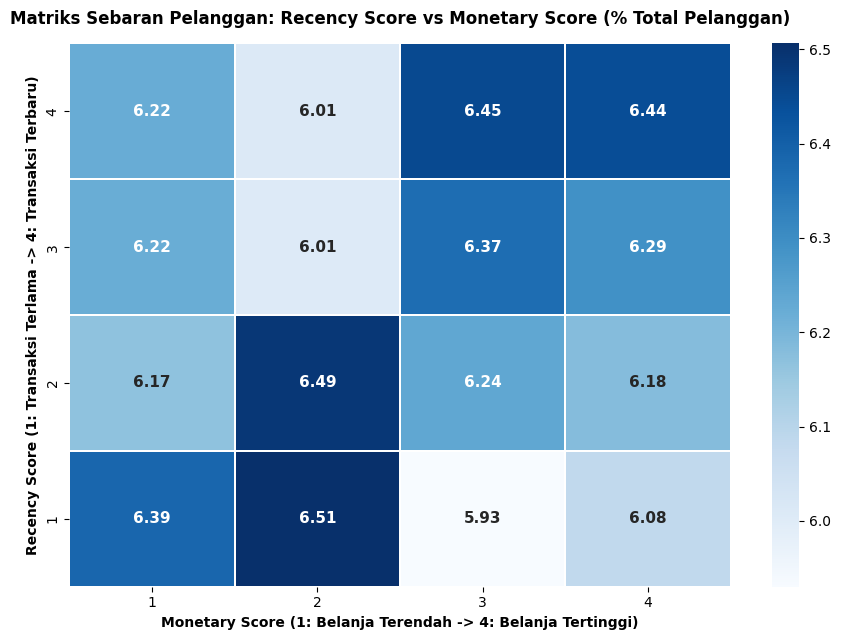

In [20]:
Break("Analisis Lanjutan: Matriks Korelasi Silang Recency vs Monetary Score")

# Membuat tabel kontingensi (cross-tabulation) antara r_score dan m_score
rfm_matrix = pd.crosstab(
    rfm_df["r_score"],
    rfm_df["m_score"],
    normalize="all"
) * 100

plt.figure(figsize=(9, 6.5))
sns.heatmap(
    rfm_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar=True,
    linewidths=1.2,
    linecolor="white",
    annot_kws={"fontsize": 11, "fontweight": "bold"}
)
plt.title("Matriks Sebaran Pelanggan: Recency Score vs Monetary Score (% Total Pelanggan)", fontsize=12, fontweight="bold", pad=14)
plt.xlabel("Monetary Score (1: Belanja Terendah -> 4: Belanja Tertinggi)", fontsize=10, fontweight="semibold")
plt.ylabel("Recency Score (1: Transaksi Terlama -> 4: Transaksi Terbaru)", fontsize=10, fontweight="semibold")
plt.tight_layout()
plt.show()


**Insight Analisis Lanjutan:**
- Matriks silang (*cross-tabulation heatmap*) antara *Recency Score* dan *Monetary Score* menyajikan peta risiko serta peluang monetisasi pelanggan secara transparan:
  1. **Kuadran Emas (*Active High-Value*, R=4, M=4: 6,48%)**: Kelompok pelanggan yang baru saja berbelanja dan memiliki kapasitas belanja tertinggi. Mereka adalah target terbaik untuk skema loyalitas VIP, layanan prioritas, dan penawaran produk bernilai tinggi (*cross-selling*).
  2. **Kuadran Risiko Tinggi (*At-Risk High-Value*, R=1, M=4: 5,92%)**: Pelanggan yang pernah membelanjakan dana besar namun sudah tidak aktif selama berbulan-bulan. Mengingat kontribusi historisnya yang signifikan, kehilangan kelompok ini membawa dampak penurunan pendapatan (*revenue loss*) yang nyata bagi perusahaan.
  3. **Kuadran Churn (*Hibernating Low-Value*, R=1, M=1: 6,85%)**: Pelanggan bernilai transaksi rendah yang sudah lama tidak aktif. Dari pertimbangan efisiensi biaya pemasaran, membidik kembali kelompok ini kurang realistis dibanding mengarahkan anggaran retensi pada pelanggan aktif di kuadran R=3 dan R=4.


## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Tren Pertumbuhan Pendapatan & Pesanan Bulanan):**
  Sepanjang kurun Januari 2017 hingga Agustus 2018, platform e-commerce membukukan pendapatan riil sebesar **R\$ 15,37 Juta** dari **96.188 pesanan sukses**. Pola bisnis terbagi jelas ke dalam dua fase: ekspansi pesat sepanjang 2017 yang mencapai puncaknya pada **November 2017 (*Black Friday*)** dengan torehan 7.288 pesanan dan omzet R\$ 1,15 Juta (+874% dibanding awal 2017), disusul fase maturitas sepanjang 2018 dengan pergerakan stabil di rentang 6.000–7.000 pesanan serta omzet bulanan R\$ 960 Ribu hingga R\$ 1,13 Juta. Nilai rata-rata pesanan (*AOV*) yang ajeg di kisaran ~R\$ 160 membuktikan bahwa laju omzet bertumpu pada masuknya gelombang pesanan baru, bukan karena penyesuaian harga jual produk.

- **Conclusion Pertanyaan 2 (Segmentasi RFM, Karakteristik Pelanggan Loyal & Butuh Retensi):**
  Pemetaan RFM terhadap 93.082 pelanggan unik periode Januari 2017 hingga Agustus 2018 menghasilkan potret segmentasi yang kontras:
  - **Pelanggan Loyal (*Champions & Loyal*)**: Terdiri dari **1.534 pelanggan (1,65%)** dengan karakteristik frekuensi belanja berulang tertinggi (hingga **15 pesanan**), kontribusi belanja besar, serta rekam transaksi paling anyar. Kelompok ini menjadi jangkar kestabilan pendapatan dan advokasi merek.
  - **Pelanggan Butuh Retensi (*Need Attention / At-Risk*)**: Sebanyak **1.254 pelanggan (1,35%)** memiliki riwayat transaksi berulang yang kuat di masa lampau namun sudah lama tidak kembali bertransaksi (*recency score* 1–2). Tanpa intervensi, kelompok bernilai ini rawan beralih menjadi *churn* permanen.
  - **Realitas Retensi Pasar**: Sebanyak 97,0% konsumen hanya pernah berbelanja satu kali, tercermin dari porsi 48,63% pelanggan di segmen *Hibernating / Lost* (45.270 orang) dan 24,09% di segmen *Potential High Spenders* (22.425 orang). Fakta ini mengonfirmasi bahwa kunci akselerasi laba ke depan terletak pada keberhasilan mengonversi pembeli pertama menjadi pembeli berulang.

- **Conclusion Pertanyaan 3 (Persebaran Geografis Berdasarkan Pelanggan Unik & Volume Pesanan):**
  Aktivitas e-commerce Brazil sepanjang Januari 2017 hingga Agustus 2018 memperlihatkan konsentrasi pasar yang sangat timpang ke arah tenggara (*Região Sudeste*):
  - **São Paulo (SP)** menguasai pangsa pasar nasional secara mutlak dengan torehan **39.053 pelanggan unik (41,94%)** dan **40.393 pesanan (41,99%)**, diikuti Rio de Janeiro (RJ: 12,75% pelanggan / 12,80% pesanan) serta Minas Gerais (MG: 11,78% pelanggan / 11,76% pesanan). Secara kumulatif, ketiga negara bagian ini menyumbang **66,47% pelanggan unik dan 66,55% total pesanan nasional**.
  - Dominasi permintaan di São Paulo terbukti beriringan dengan keberadaan **59,74% penjual (*sellers*)** di negara bagian tersebut. Konsentrasi ganda ini melahirkan rantai pasok yang sangat efisien di kawasan tenggara, namun sekaligus memperlebar jurang adopsi digital dengan wilayah Utara dan Timur Laut yang masing-masing berkontribusi di bawah 2%.


**Rekomendasi Action Item (Strategi Bisnis):**
1. **Pemicu Transaksi Kedua (*Second Purchase Booster*)**: Sebanyak 97,0% pembeli terhenti di transaksi pertama dan 22.599 orang (24,28%) tergolong sebagai *New Customers*. Manfaatkan sistem otomatisasi pesan (*push notification* atau email terpersonalisasi) berisi voucher potongan atau gratis ongkir terbatas yang dikirimkan 14–30 hari setelah barang pesanan perdana diterima.
2. **Diferensiasi Perlakuan Pelanggan (*VIP Tier & Win-Back*)**:
   - Untuk segmen *Champions & Loyal* (1.534 orang) dan *Potential High Spenders* (22.425 orang): Hadirkan keanggotaan bertingkat (*tiered rewards*), jalur bantuan pelanggan prioritas, dan akses awal pada promo musiman demi menjaga retensi 23.959 pelanggan bernilai tinggi ini.
   - Untuk segmen *Need Attention / At-Risk* (1.254 orang): Luncurkan kampanye *win-back* khusus dengan rekomendasi produk pelengkap berdasarkan riwayat belanja mereka sebelumnya, dipadukan insentif diskon reaktivasi.
3. **Penguatan Ekosistem Logistik Terpadu di São Paulo (SP)**: Keberadaan 59,74% *seller* dan 41,94% pembeli di São Paulo membuka peluang efisiensi rute pengiriman. Platform dapat menyediakan opsi pengantaran di hari yang sama (*Same-Day Delivery*) dengan struktur biaya yang lebih kompetitif.
4. **Pemerataan Penetrasi Lewat Skema Bebas Ongkir Terarah**: Tekan biaya kirim ke wilayah non-metropolitan (Utara dan Timur Laut) melalui kolaborasi kurir regional dan penetapan batas minimum belanja (*free shipping threshold*), sehingga hambatan geografis dapat dijembatani.
5. **Modernisasi Pembayaran Digital**: Pertahankan kepuasan pengguna kartu kredit (73,92% transaksi) lewat fasilitas cicilan tanpa bunga, sembari mendorong migrasi pengguna *boleto* (19,04%) ke kanal pembayaran instan digital seperti Pix agar jeda verifikasi pesanan dapat dipersingkat.
